In [1]:
import spectral
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
input_path = '/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/351_1_240506-160920/capture/351_1_240506-160920.hdr'
output_dir = '/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing'
output_path = os.path.join(output_dir, 'espectros_swir_351_1.csv')

img_spectral = envi.open(input_path)

print(f"Imagem carregada: {img_spectral}")
print(f"Dimensões: {img_spectral.shape}")

/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/.venv/lib/python3.11/site-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)
/tmp/ipykernel_16500/2182210059.py:41: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  roi = img * mask3d


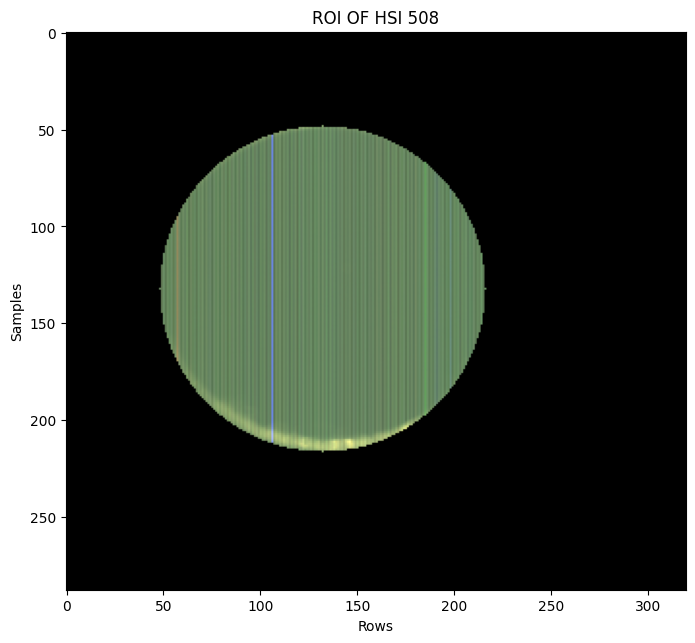

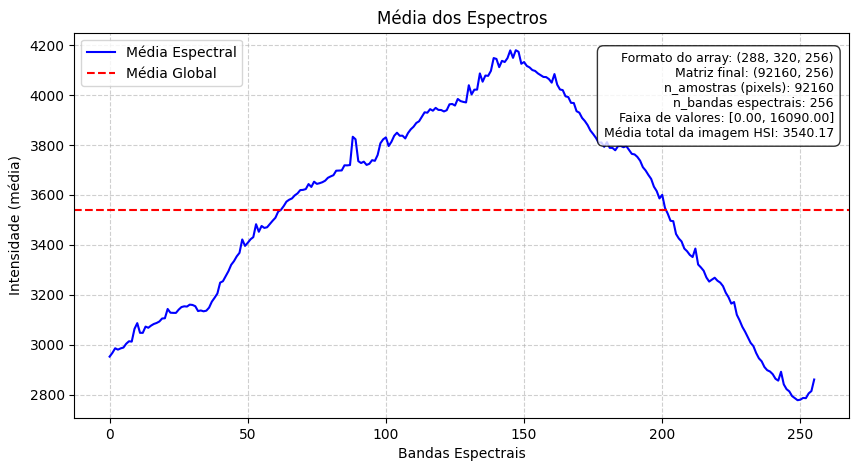

In [ ]:
# Plot da média espectral
plt.figure(figsize=(10, 5))
plt.plot(range(n_bandas), media_espectro, label="Média Espectral", color='blue')

plt.xlabel("Bandas Espectrais")
plt.ylabel("Intensidade (média)")
plt.title("Média dos Espectros")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Caixa de informações (apenas texto)
info_text = (
    f"Formato do array: {img.shape}\n"
    f"Matriz final: {espectros_matriz.shape}\n"
    f"n_amostras (pixels): {n_amostras}\n"
    f"n_bandas espectrais: {n_bandas}\n"
    f"Faixa de valores: [{espectros_matriz.min():.2f}, {espectros_matriz.max():.2f}]\n"
    f"Média total da imagem HSI: {media_total:.2f}"
)

plt.text(
    0.98, 0.95, info_text,
    transform=plt.gca().transAxes,
    fontsize=9, va="top", ha="right",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8)
)

plt.show()


/tmp/ipykernel_2575/1434227114.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  roi = img * mask3d
/tmp/ipykernel_2575/1434227114.py:54: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


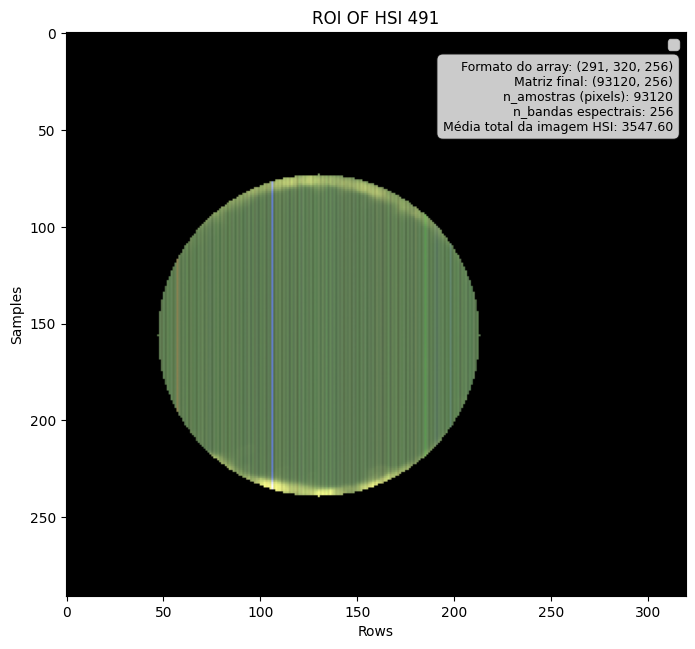

In [6]:
# Carregar HSI como numpy array
img = spectral.open_image(
    "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/491_240506-160846/capture/491_240506-160846.hdr"
).load()

# Criar imagem RGB para visualização
rgb = spectral.get_rgb(img, [50, 30, 10])

gray = cv2.cvtColor((rgb * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
gray = cv2.GaussianBlur(gray, (7, 7), 2)

circles = cv2.HoughCircles(
    gray,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=100,
    param1=100,
    param2=30,
    minRadius=50,
    maxRadius=200
)

mask = np.zeros(gray.shape, dtype=np.uint8)

if circles is not None:
    x, y, r = circles[0][0]
    cv2.circle(mask, (int(x), int(y)), int(r), 1, thickness=-1)

mask3d = np.repeat(mask[:, :, np.newaxis], img.shape[2], axis=2)

roi = img * mask3d

roi_rgb = spectral.get_rgb(roi, [50, 30, 10])
roi_rgb_norm = roi_rgb / roi_rgb.max()

# Obter dimensões da imagem
altura, largura, n_bandas = img.shape
img_array = img  # Para manter consistência com seu f-string

# Número total de pixels (amostras)
n_amostras = altura * largura

# Transformar a imagem em matriz 2D (pixels x bandas)
espectros_matriz = img.reshape(n_amostras, n_bandas)

# Média global da imagem
media_total = espectros_matriz.mean()

plt.figure(figsize=(8, 8))
plt.imshow(roi_rgb_norm)
plt.title("ROI OF HSI 491")
plt.xlabel("Rows")
plt.ylabel("Samples")
plt.legend()
# Caixa de informações no gráfico
info_text = (
    f"Formato do array: {img_array.shape}\n"
    f"Matriz final: {espectros_matriz.shape}\n"
    f"n_amostras (pixels): {n_amostras}\n"
    f"n_bandas espectrais: {n_bandas}\n"
    f"Média total da imagem HSI: {media_total:.2f}"
)

plt.text(
    0.98, 0.95, info_text,
    transform=plt.gca().transAxes,
    fontsize=9, va="top", ha="right",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8)
)
plt.savefig("roi_hsi_491.png", dpi=300, bbox_inches='tight')
plt.show()




/tmp/ipykernel_2575/3828496631.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  roi = img * mask3d


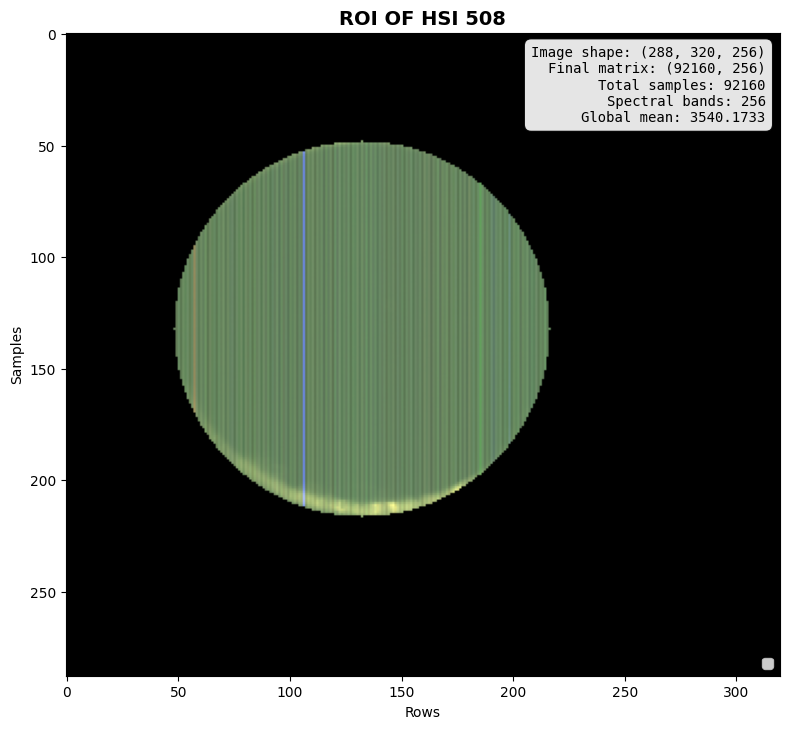

In [ ]:
import spectral
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = spectral.open_image(
    "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/508_240506-160326/capture/508_240506-160326.hdr"
).load()

rgb = spectral.get_rgb(img, [50, 30, 10])

gray = cv2.cvtColor((rgb * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
gray = cv2.GaussianBlur(gray, (7, 7), 2)

circles = cv2.HoughCircles(
    gray,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=100,
    param1=100,
    param2=30,
    minRadius=50,
    maxRadius=200
)

mask = np.zeros(gray.shape, dtype=np.uint8)

if circles is not None:
    x, y, r = circles[0][0]
    cv2.circle(mask, (int(x), int(y)), int(r), 1, thickness=-1)

mask3d = np.repeat(mask[:, :, np.newaxis], img.shape[2], axis=2)

roi = img * mask3d

roi_rgb = spectral.get_rgb(roi, [50, 30, 10])
roi_rgb_norm = roi_rgb / roi_rgb.max()

altura, largura, n_bandas = img.shape
img_array = img 

n_amostras = altura * largura

# Transformar a imagem em matriz 2D (pixels x bandas)
espectros_matriz = img.reshape(n_amostras, n_bandas)

media_total = espectros_matriz.mean()


plt.figure(figsize=(8, 8))
plt.imshow(roi_rgb_norm)
plt.title("ROI OF HSI 508")
plt.xlabel("Rows")
plt.ylabel("Samples")

plt.legend()

info_text = (
    f"Formato do array: {img_array.shape}\n"
    f"Matriz final: {espectros_matriz.shape}\n"
    f"n_amostras (pixels): {n_amostras}\n"
    f"n_bandas espectrais: {n_bandas}\n"
    f"Média total da imagem HSI: {media_total:.2f}"
)

plt.text(
    0.98, 0.95, info_text,
    transform=plt.gca().transAxes,
    fontsize=9, va="top", ha="right",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8)
)
plt.savefig("roi_hsi_508.png", dpi=300, bbox_inches='tight')
plt.show()




Mostrar a média entre a HSI 508 & 491

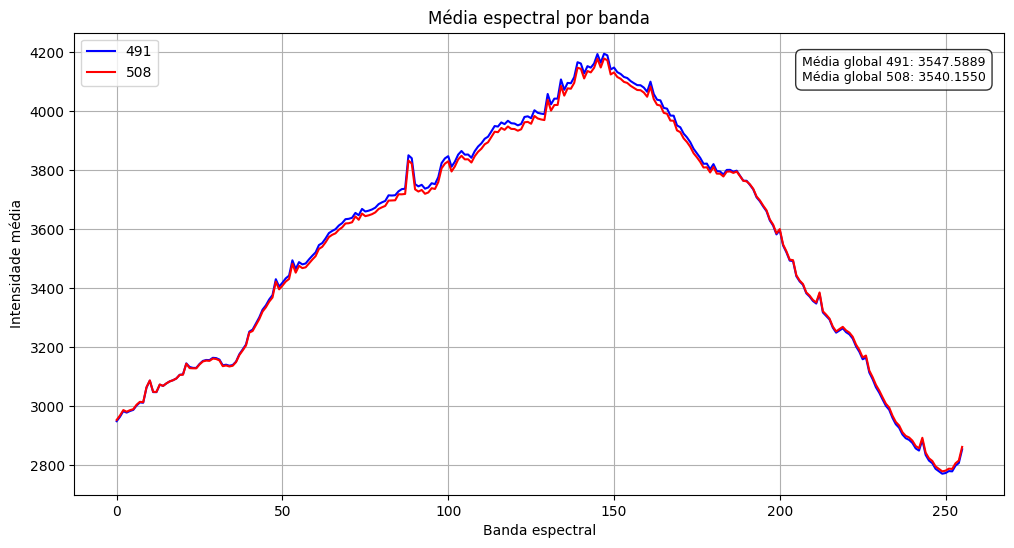

In [15]:
import spectral
import numpy as np
import matplotlib.pyplot as plt

# --- Imagem 491 ---
img_491 = spectral.open_image(
    "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/491_240506-160846/capture/491_240506-160846.hdr"
).load()

altura, largura, n_bandas = img_491.shape
espectros_matriz_491 = img_491.reshape(altura * largura, n_bandas)
media_491 = espectros_matriz_491.mean(axis=0)
media_total_491 = media_491.mean()

# --- Imagem 508 ---
img_508 = spectral.open_image(
    "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/508_240506-160326/capture/508_240506-160326.hdr"
).load()

altura, largura, n_bandas = img_508.shape
espectros_matriz_508 = img_508.reshape(altura * largura, n_bandas)
media_508 = espectros_matriz_508.mean(axis=0)
media_total_508 = media_508.mean()

# --- Plot ---
plt.figure(figsize=(12,6))
plt.plot(media_491, label="491", color='blue')
plt.plot(media_508, label="508", color='red')
plt.title("Média espectral por banda")
plt.xlabel("Banda espectral")
plt.ylabel("Intensidade média")
plt.grid(True)

plt.legend()
# Caixa de informações no gráfico
info_text = (
    f"Média global 491: {media_total_491:.4f}\n"
    f"Média global 508: {media_total_508:.4f}"
)

plt.text(
    0.98, 0.95, info_text,
    transform=plt.gca().transAxes,
    fontsize=9, va="top", ha="right",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8)
)

plt.savefig("Média espectral por banda.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
input_path = '/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/351_1_240506-160920/capture/351_1_240506-160920.hdr'
